In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("/content/Breast_Cancer-selected-columns.csv")
df

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size
0,68,White,Married,NaN,N1,IIA,Poorly differentiated,3,Regional,4
1,50,White,Married,NaN,N2,IIIA,Moderately differentiated,2,Regional,35
2,58,White,Divorced,NaN,N3,IIIC,Moderately differentiated,2,Regional,63
3,58,White,Married,NaN,N1,IIA,Poorly differentiated,3,Regional,18
4,47,White,Married,NaN,N1,IIB,Poorly differentiated,3,Regional,41
...,...,...,...,...,...,...,...,...,...,...
4019,62,Other,Married,NaN,N1,IIA,Moderately differentiated,2,Regional,9
4020,56,White,Divorced,NaN,N2,IIIA,Moderately differentiated,2,Regional,46
4021,68,White,Married,NaN,N1,IIB,Moderately differentiated,2,Regional,22
4022,58,Black,Divorced,NaN,N1,IIB,Moderately differentiated,2,Regional,44


In [3]:
df.head()

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size
0,68,White,Married,NaN,N1,IIA,Poorly differentiated,3,Regional,4
1,50,White,Married,NaN,N2,IIIA,Moderately differentiated,2,Regional,35
2,58,White,Divorced,NaN,N3,IIIC,Moderately differentiated,2,Regional,63
3,58,White,Married,NaN,N1,IIA,Poorly differentiated,3,Regional,18
4,47,White,Married,NaN,N1,IIB,Poorly differentiated,3,Regional,41


In [4]:
df.tail()

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size
4019,62,Other,Married,NaN,N1,IIA,Moderately differentiated,2,Regional,9
4020,56,White,Divorced,NaN,N2,IIIA,Moderately differentiated,2,Regional,46
4021,68,White,Married,NaN,N1,IIB,Moderately differentiated,2,Regional,22
4022,58,Black,Divorced,NaN,N1,IIB,Moderately differentiated,2,Regional,44
4023,46,White,Married,NaN,N1,IIB,Moderately differentiated,2,Regional,30


In [5]:
df.shape

(4024, 10)

In [7]:
df.columns

Index(['Age', 'Race', 'Marital Status', 'T Stage', 'N Stage', '6th Stage',
       'differentiate', 'Grade', 'A Stage', 'Tumor Size'],
      dtype='object')

In [8]:
df.describe()

,Age,T Stage,Tumor Size
count,4024.000000,0.0,4024.000000
mean,53.972167,NaN,30.473658
std,8.963134,NaN,21.119696
min,30.000000,NaN,1.000000
25%,47.000000,NaN,16.000000
50%,54.000000,NaN,25.000000
75%,61.000000,NaN,38.000000
max,69.000000,NaN,140.000000


In [9]:
df.info(
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4024 entries, 0 to 4023
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             4024 non-null   int64  
 1   Race            4024 non-null   object 
 2   Marital Status  4024 non-null   object 
 3   T Stage         0 non-null      float64
 4   N Stage         4024 non-null   object 
 5   6th Stage       4024 non-null   object 
 6   differentiate   4024 non-null   object 
 7   Grade           4024 non-null   object 
 8   A Stage         4024 non-null   object 
 9   Tumor Size      4024 non-null   int64  
dtypes: float64(1), int64(2), object(7)
memory usage: 314.5+ KB


In [12]:
df.sample(n=100)

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size
3538,59,White,Divorced,NaN,N3,IIIC,Poorly differentiated,3,Regional,35
1147,41,White,Married,NaN,N1,IIA,Well differentiated,1,Regional,7
186,68,White,Married,NaN,N1,IIIA,Moderately differentiated,2,Regional,68
2191,65,White,Widowed,NaN,N2,IIIA,Moderately differentiated,2,Regional,30
2386,48,White,Widowed,NaN,N1,IIA,Well differentiated,1,Regional,19
...,...,...,...,...,...,...,...,...,...,...
2968,63,White,Married,NaN,N1,IIA,Moderately differentiated,2,Regional,15
3414,41,White,Married,NaN,N1,IIB,Moderately differentiated,2,Regional,23
2070,48,White,Divorced,NaN,N1,IIA,Poorly differentiated,3,Regional,17
3133,55,White,Married,NaN,N1,IIIA,Moderately differentiated,2,Regional,55


In [13]:
summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Missing %": (df.isnull().sum() / len(df) * 100).round(2),
    "Unique Values": df.nunique()
})

summary.sort_values("Missing %", ascending=False)

,Data Type,Missing Values,Missing %,Unique Values
T Stage,float64,4024,100.0,0
Age,int64,0,0.0,40
Race,object,0,0.0,3
Marital Status,object,0,0.0,5
N Stage,object,0,0.0,3
6th Stage,object,0,0.0,5
differentiate,object,0,0.0,4
Grade,object,0,0.0,4
A Stage,object,0,0.0,2
Tumor Size,int64,0,0.0,110


In [14]:
df_cleaned = df.drop(columns=['T Stage'])
df_cleaned = df_cleaned.drop_duplicates()
print(f"Original shape: {df.shape}")
print(f"Cleaned shape: {df_cleaned.shape}")

Original shape: (4024, 10)
Cleaned shape: (3519, 9)


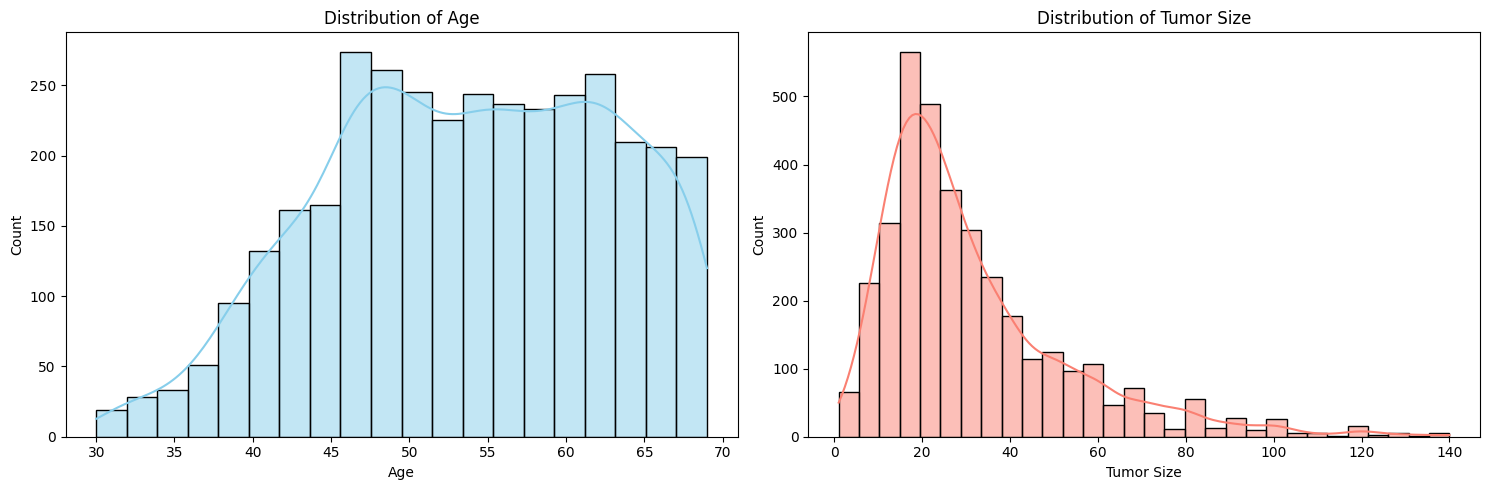

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(df_cleaned['Age'], bins=20, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Age')
sns.histplot(df_cleaned['Tumor Size'], bins=30, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Tumor Size')
plt.tight_layout()
plt.show()

/tmp/ipykernel_7824/1295472717.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_cleaned, y=col, ax=axes[i], order=df_cleaned[col].value_index if hasattr(df_cleaned[col], 'value_index') else df_cleaned[col].value_counts().index, palette='viridis')
/tmp/ipykernel_7824/1295472717.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_cleaned, y=col, ax=axes[i], order=df_cleaned[col].value_index if hasattr(df_cleaned[col], 'value_index') else df_cleaned[col].value_counts().index, palette='viridis')
/tmp/ipykernel_7824/1295472717.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and

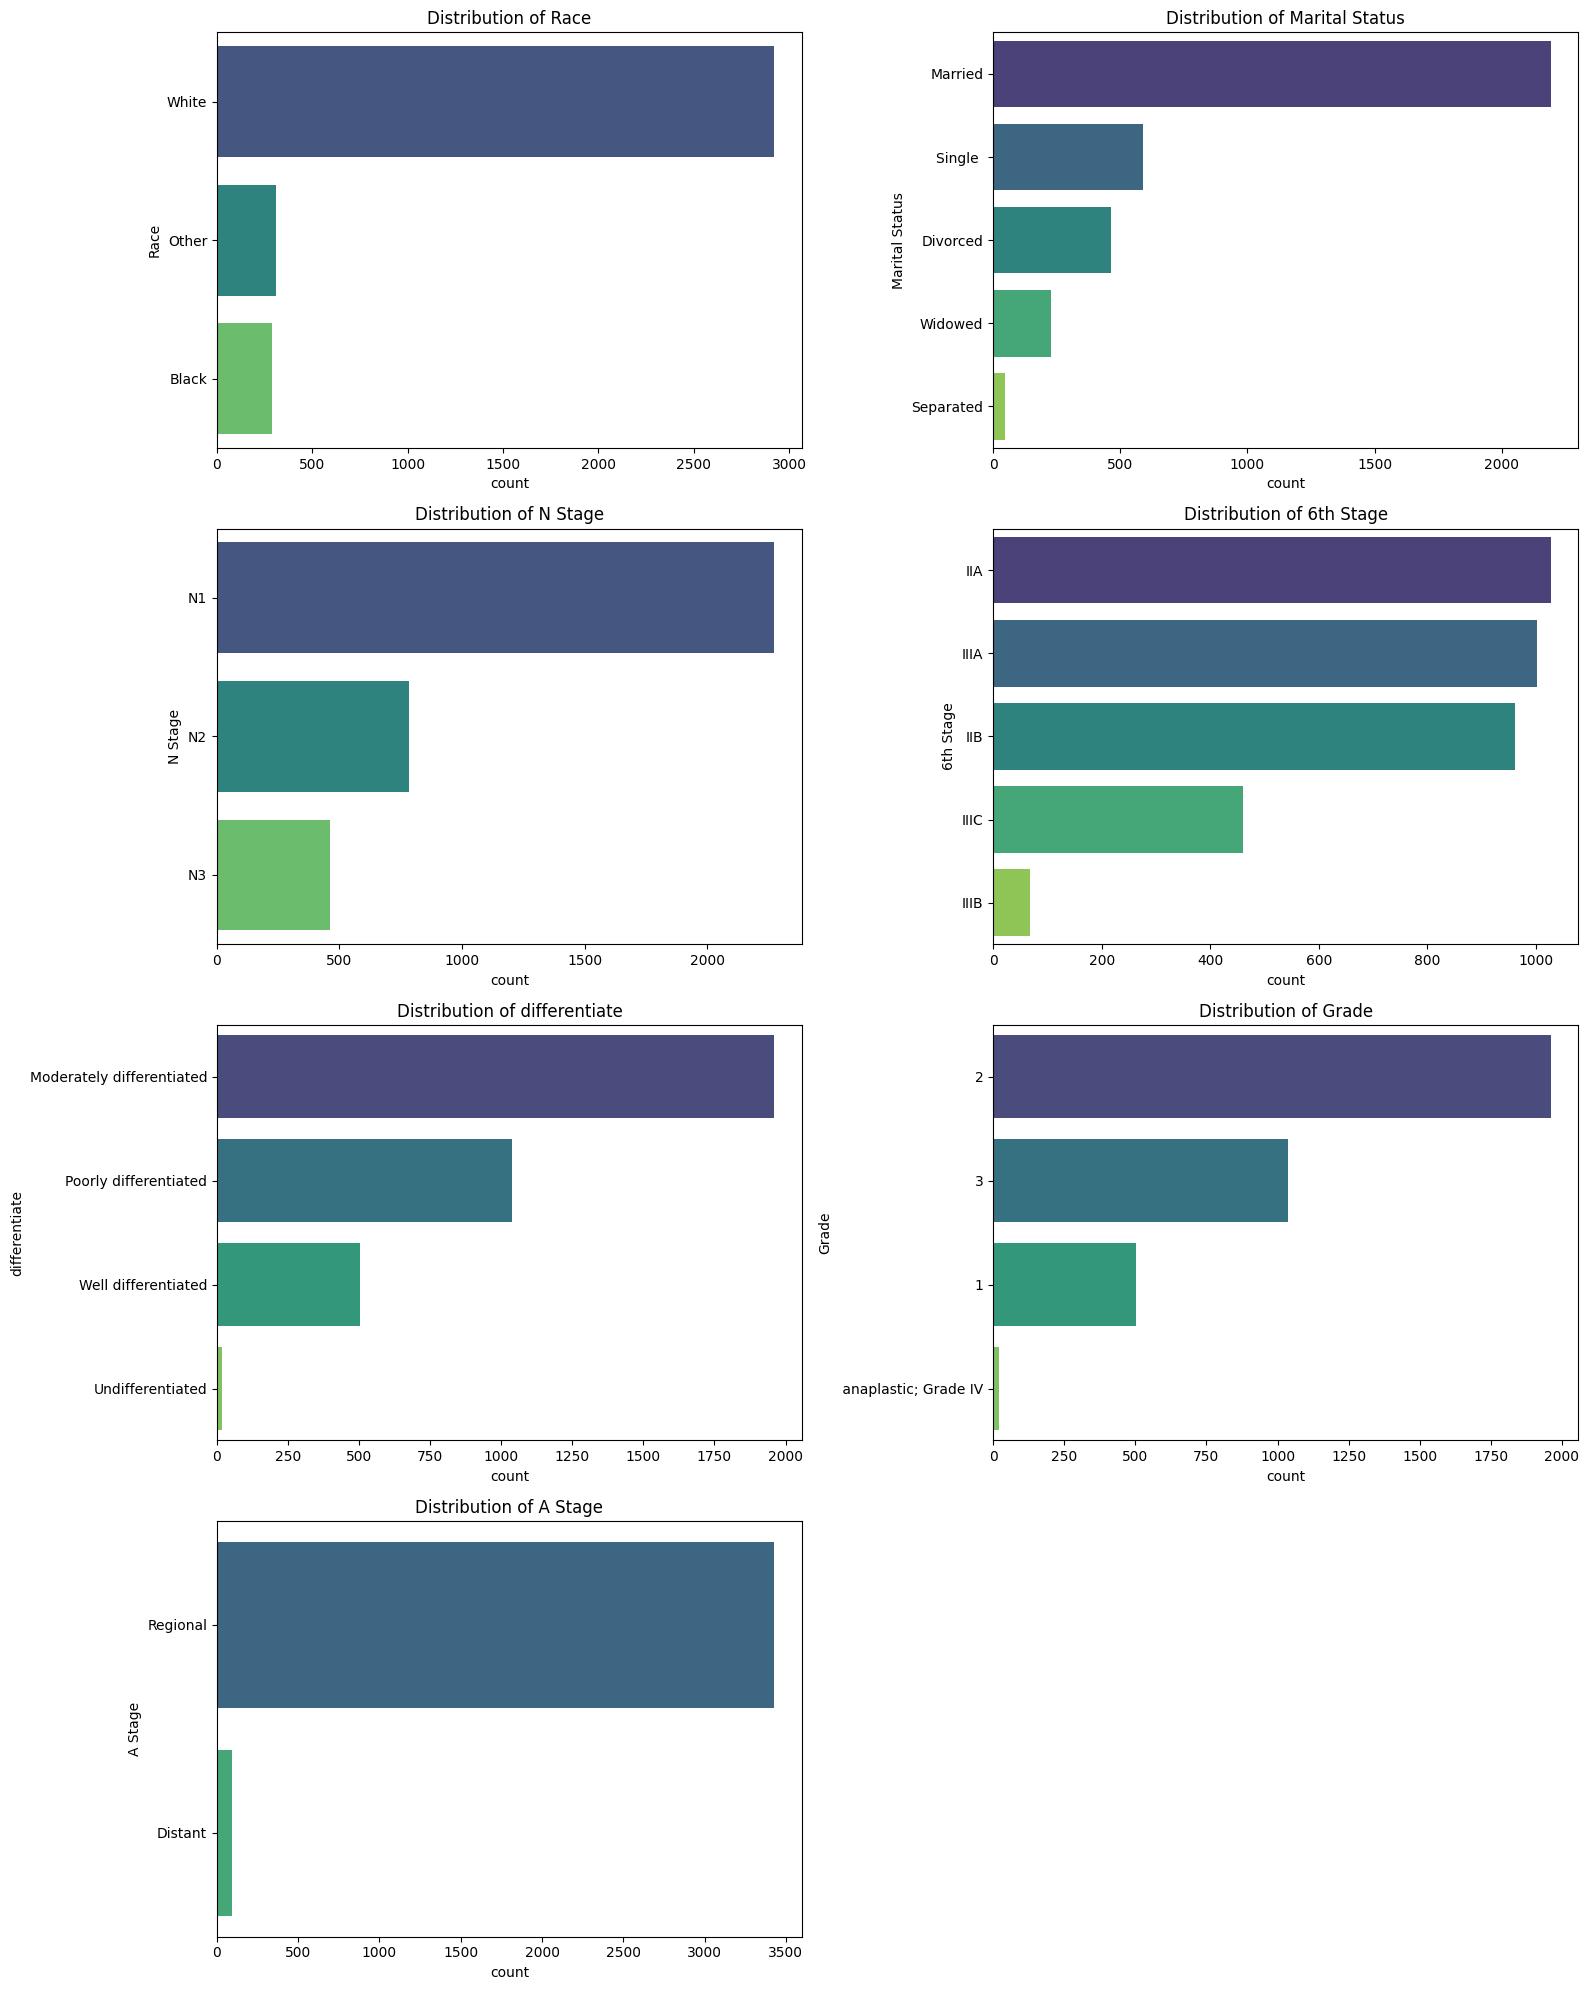

In [22]:
categorical_cols = ['Race', 'Marital Status', 'N Stage', '6th Stage', 'differentiate', 'Grade', 'A Stage']
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()
for i, col in enumerate(categorical_cols):
    sns.countplot(data=df_cleaned, y=col, ax=axes[i], order=df_cleaned[col].value_index if hasattr(df_cleaned[col], 'value_index') else df_cleaned[col].value_counts().index, palette='viridis')
    axes[i].set_title(f'Distribution of {col}')
if len(categorical_cols) < len(axes):
    fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

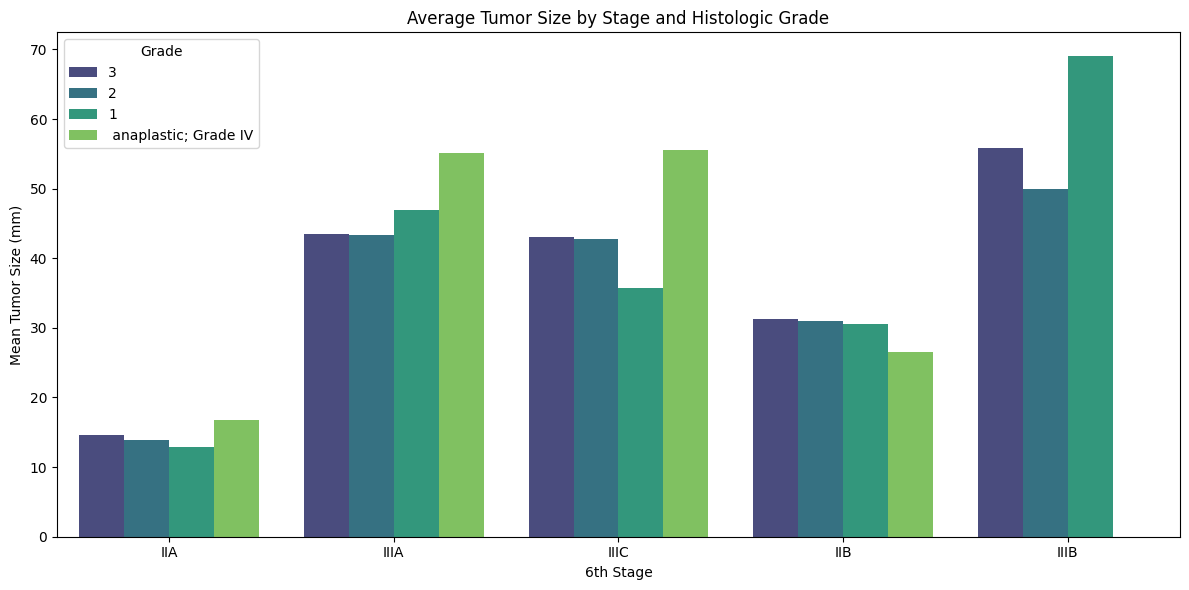

In [17]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df_cleaned, x='6th Stage', y='Tumor Size', hue='Grade', errorbar=None, palette='viridis')
plt.title('Average Tumor Size by Stage and Histologic Grade')
plt.ylabel('Mean Tumor Size (mm)')
plt.xlabel('6th Stage')
plt.tight_layout()
plt.show()

In [18]:
cross_tab = pd.crosstab(df_cleaned['6th Stage'], df_cleaned['Grade'], normalize='index') * 100
print("Percentage Distribution of Histologic Grade within each Clinical Stage (6th Stage):")
print(cross_tab.round(2))

Percentage Distribution of Histologic Grade within each Clinical Stage (6th Stage):
Grade       anaplastic; Grade IV      1      2      3
6th Stage                                            
IIA                         0.39  21.52  56.48  21.62
IIB                         0.21  14.55  55.72  29.52
IIIA                        0.80  10.08  58.48  30.64
IIIB                        0.00  11.94  52.24  35.82
IIIC                        1.08   7.16  48.37  43.38


In [19]:
df_cleaned['Age Group'] = pd.cut(df_cleaned['Age'], bins=[0, 39, 49, 59, 69, 100], labels=['<40', '40-49', '50-59', '60-69', '70+'])
df_cleaned['Tumor Size Category'] = pd.cut(df_cleaned['Tumor Size'], bins=[0, 20, 50, 150], labels=['Small (<=20mm)', 'Medium (21-50mm)', 'Large (>50mm)'])
df_cleaned[['Age', 'Age Group', 'Tumor Size', 'Tumor Size Category']].head()

,Age,Age Group,Tumor Size,Tumor Size Category
0,68,60-69,4,Small (<=20mm)
1,50,50-59,35,Medium (21-50mm)
2,58,50-59,63,Large (>50mm)
3,58,50-59,18,Small (<=20mm)
4,47,40-49,41,Medium (21-50mm)


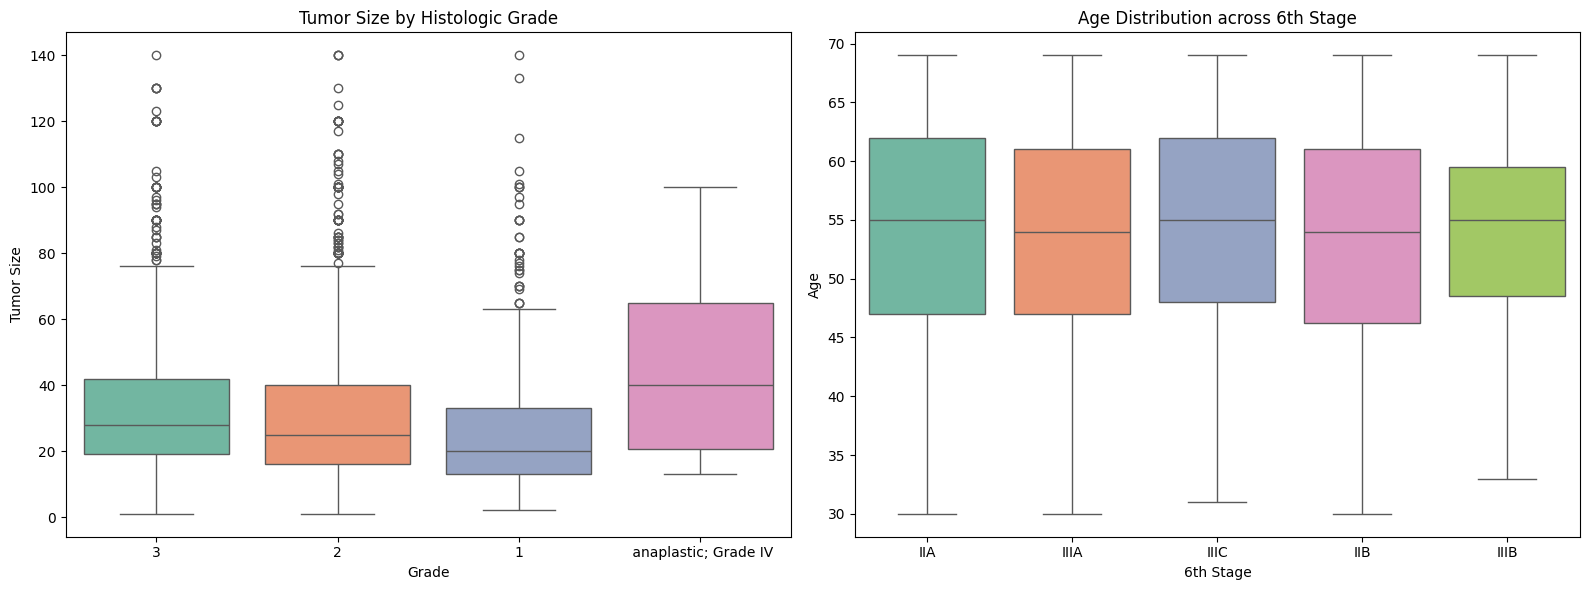

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=df_cleaned, x='Grade', y='Tumor Size', ax=axes[0], palette='Set2', hue='Grade', legend=False)
axes[0].set_title('Tumor Size by Histologic Grade')
sns.boxplot(data=df_cleaned, x='6th Stage', y='Age', ax=axes[1], palette='Set2', hue='6th Stage', legend=False)
axes[1].set_title('Age Distribution across 6th Stage')
plt.tight_layout()
plt.show()

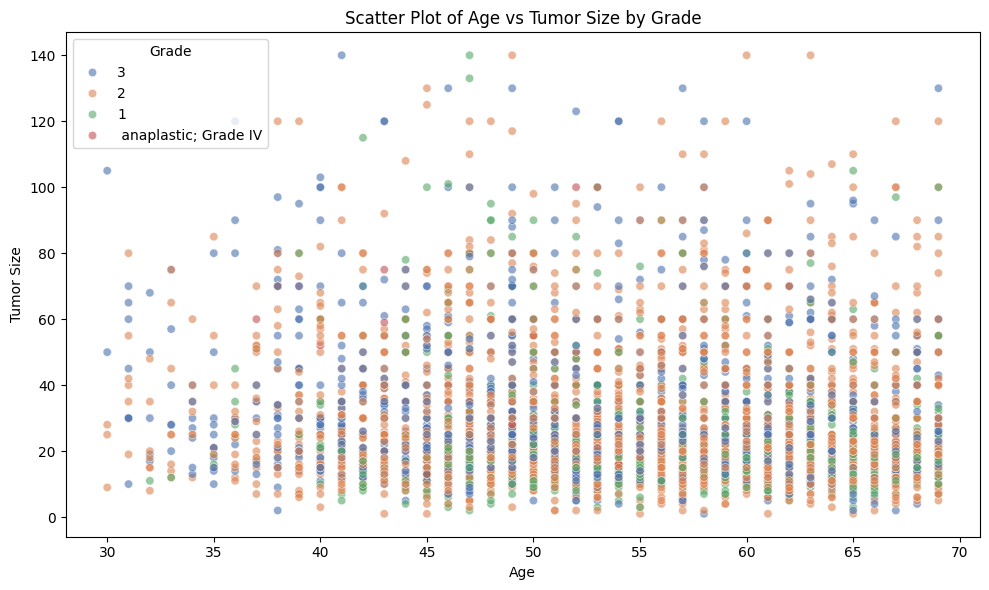

In [21]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_cleaned, x='Age', y='Tumor Size', hue='Grade', alpha=0.6, palette='deep')
plt.title('Scatter Plot of Age vs Tumor Size by Grade')
plt.tight_layout()
plt.show()